# ❤️ Heart Disease Predictor: Logistic Regression

**Goal:** Predict whether a patient is likely to have heart disease from 13 medical measurements (age, blood pressure, cholesterol, heart rate, chest pain type, and so on).

**Problem type:** Binary classification (0 = no heart disease, 1 = heart disease)

**Dataset:** UCI Heart Disease (Cleveland), about 300 patients, 13 features

**Models compared:** A baseline that always guesses the most common class, and Logistic Regression with different regularization strengths (`C`)

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, scikit-learn

**Workflow:** Load → Clean → EDA → Train/test split → Train and compare models (with cross-validation) → Evaluate (confusion matrix, precision, recall, ROC curve) → Interpret coefficients → Export the model for a website

> This is an educational project. It is not a medical tool and must not be used to diagnose anyone.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report)

sns.set_style("whitegrid")
RANDOM_STATE = 42

NUM_COLS = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CAT_COLS = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

## 1. Load the Data

The file has no header row, so the column names are added by hand. Missing values are marked with `?` in the file.

| Column | Meaning |
|---|---|
| age | Age in years |
| sex | Female or male |
| cp | Chest pain type |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Cholesterol (mg/dl) |
| fbs | Fasting blood sugar above 120 mg/dl |
| restecg | Resting ECG result |
| thalach | Maximum heart rate reached |
| exang | Chest pain caused by exercise |
| oldpeak | ST depression during exercise (an ECG measurement) |
| slope | Slope of the ST segment during exercise |
| ca | Number of major blood vessels (0 to 3) seen in a scan |
| thal | Thalassemia test result |
| num | Heart disease level (0 = none, 1 to 4 = present) |

In [2]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

try:
    df = pd.read_csv(URL, header=None, names=COLUMNS, na_values="?")
except Exception:
    # If the download fails, upload the file by hand
    print("Download failed. Please choose the file from your computer.")
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0], header=None, names=COLUMNS, na_values="?")

print("Shape:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
df.head()

Shape: (303, 14)

Missing values per column:
ca      4
thal    2
dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Data Cleaning

Changes made:
- Remove the few rows with missing values
- Turn `num` into a simple yes/no **target**: 1 if heart disease is present (`num` above 0), otherwise 0
- Replace the number codes with readable labels (for example, `cp` 4 becomes "Asymptomatic"), so the charts and coefficients are easy to read

In [3]:
print("Rows with missing values:", df.isnull().any(axis=1).sum())
df = df.dropna().copy()

df["target"] = (df["num"] > 0).astype(int)
df = df.drop(columns="num")

df["sex"] = df["sex"].map({0: "Female", 1: "Male"})
df["cp"] = df["cp"].map({1: "Typical angina", 2: "Atypical angina",
                         3: "Non-anginal pain", 4: "Asymptomatic"})
df["fbs"] = df["fbs"].map({0: "No", 1: "Yes"})
df["restecg"] = df["restecg"].map({0: "Normal", 1: "ST-T abnormality", 2: "LV hypertrophy"})
df["exang"] = df["exang"].map({0: "No", 1: "Yes"})
df["slope"] = df["slope"].map({1: "Upsloping", 2: "Flat", 3: "Downsloping"})
df["ca"] = df["ca"].astype(int).astype(str)
df["thal"] = df["thal"].map({3: "Normal", 6: "Fixed defect", 7: "Reversible defect"})

assert df[CAT_COLS].notnull().all().all(), "Some labels were not mapped. Check the code values."
print("Rows kept:", len(df))
df.head()

Rows with missing values: 6
Rows kept: 297


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,Male,Typical angina,145.0,233.0,Yes,LV hypertrophy,150.0,No,2.3,Downsloping,0,Fixed defect,0
1,67.0,Male,Asymptomatic,160.0,286.0,No,LV hypertrophy,108.0,Yes,1.5,Flat,3,Normal,1
2,67.0,Male,Asymptomatic,120.0,229.0,No,LV hypertrophy,129.0,Yes,2.6,Flat,2,Reversible defect,1
3,37.0,Male,Non-anginal pain,130.0,250.0,No,Normal,187.0,No,3.5,Downsloping,0,Normal,0
4,41.0,Female,Atypical angina,130.0,204.0,No,LV hypertrophy,172.0,No,1.4,Upsloping,0,Normal,0


## 3. Exploratory Data Analysis (EDA)

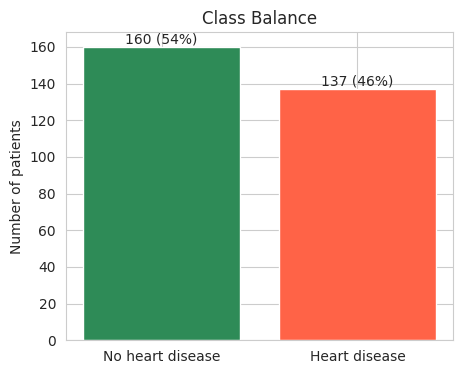

In [4]:
counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(5, 4))
plt.bar(["No heart disease", "Heart disease"], counts.values, color=["seagreen", "tomato"])
for i, v in enumerate(counts.values):
    plt.text(i, v + 2, f"{v} ({v / len(df) * 100:.0f}%)", ha="center")
plt.ylabel("Number of patients")
plt.title("Class Balance")
plt.show()

**Insight:** The two classes are fairly balanced, so accuracy is a reasonable metric here. With very unbalanced data (like fraud detection), accuracy would be misleading.

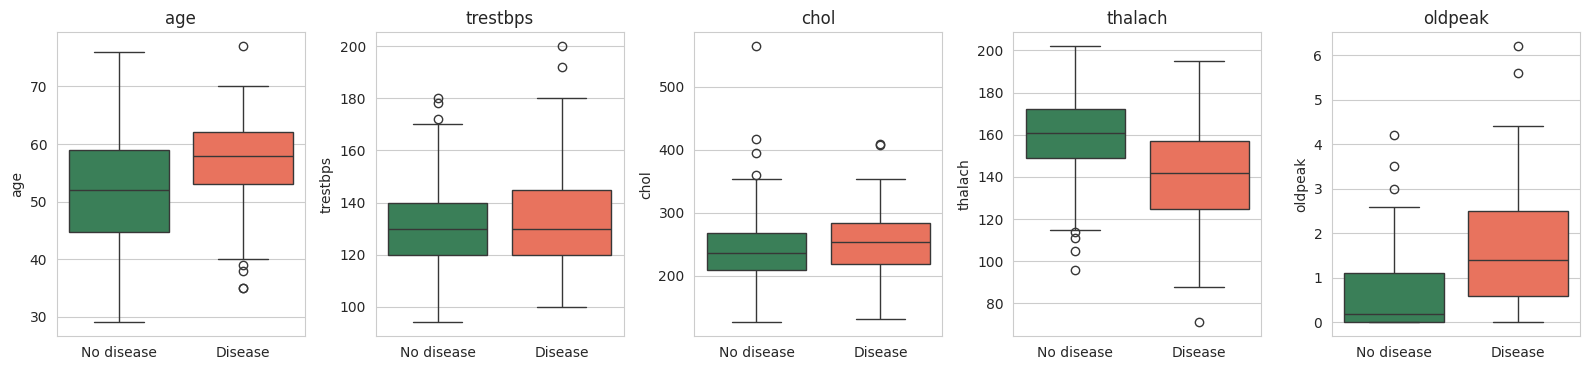

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(x="target", y=col, data=df, ax=ax, hue="target", palette=["seagreen", "tomato"], legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No disease", "Disease"])
    ax.set_xlabel("")
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Insight:** Patients with heart disease tend to reach a lower maximum heart rate (`thalach`) and show higher ST depression (`oldpeak`). Age is somewhat higher in the disease group. Blood pressure and cholesterol overlap heavily between the two groups, so they separate patients less clearly.

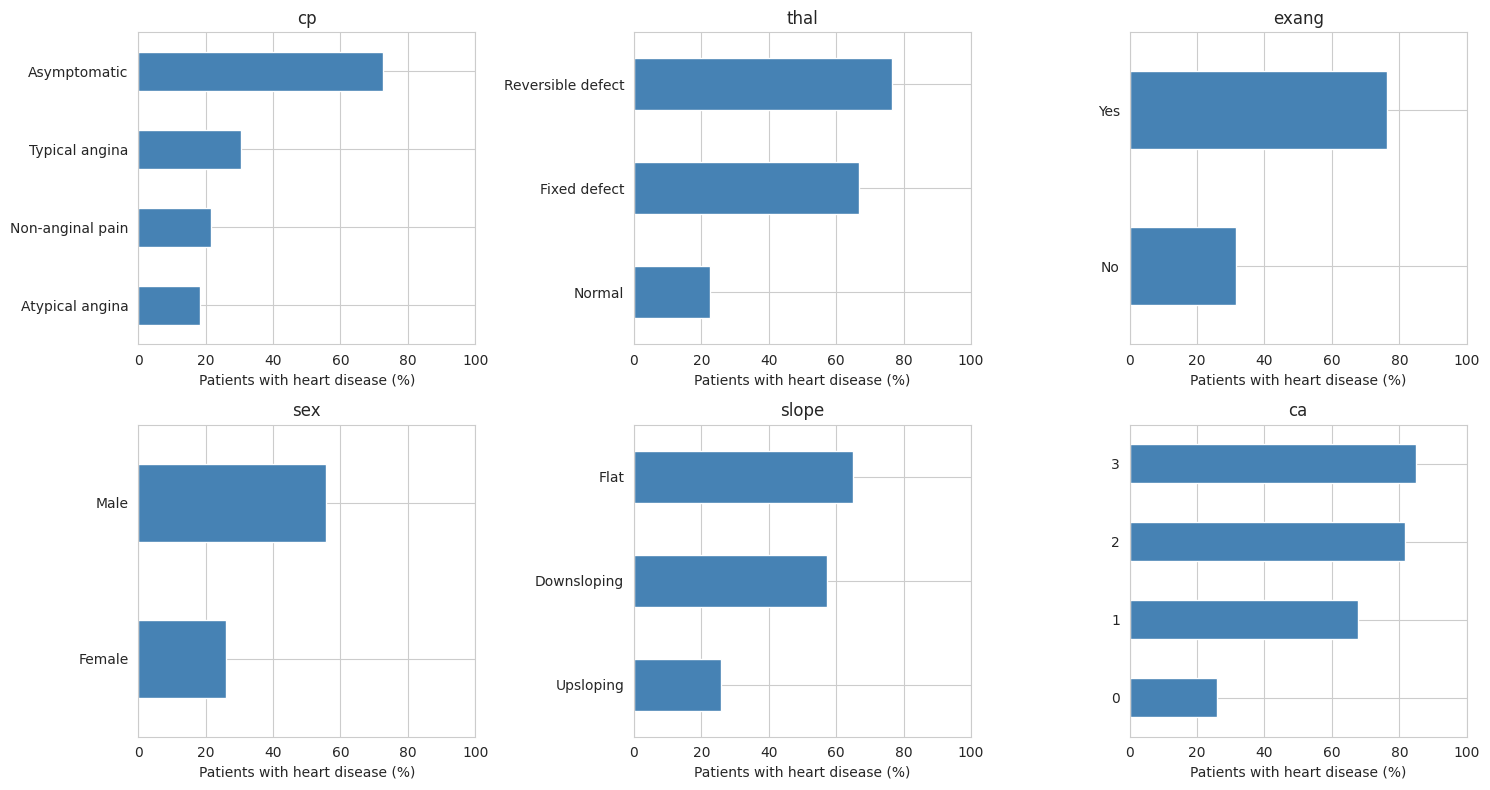

In [6]:
cat_to_plot = ["cp", "thal", "exang", "sex", "slope", "ca"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cat_to_plot):
    rate = df.groupby(col)["target"].mean() * 100
    rate.sort_values().plot(kind="barh", ax=ax, color="steelblue")
    ax.set_xlabel("Patients with heart disease (%)")
    ax.set_ylabel("")
    ax.set_title(col)
    ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

**Insight:** The disease rate changes a lot between groups. For example, patients with no chest pain symptoms (`Asymptomatic`), a reversible thalassemia defect, exercise-induced chest pain, or more blood vessels flagged in the scan (`ca`) have much higher rates. Men also show a higher rate than women in this dataset.

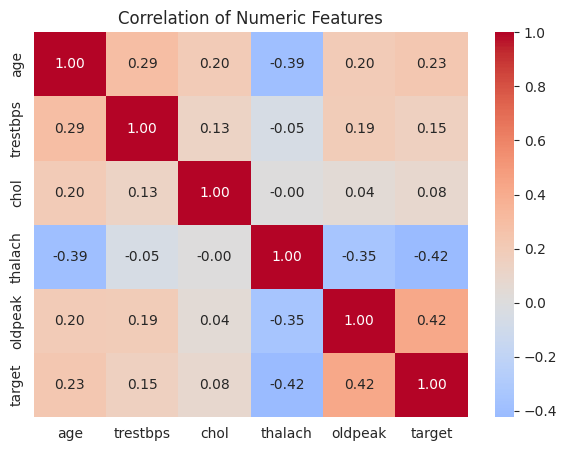

In [7]:
corr_data = df[NUM_COLS + ["target"]]
plt.figure(figsize=(7, 5))
sns.heatmap(corr_data.corr(), annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation of Numeric Features")
plt.show()

**Insight:** `oldpeak` is positively correlated with heart disease, and `thalach` (maximum heart rate) is negatively correlated. This matches the box plots above.

## 4. Train/Test Split

`stratify=y` keeps the same share of disease and no-disease patients in both sets. The dataset is small, so the test set holds only about 60 patients. One patient is worth roughly 1.7 percentage points of accuracy, so test results can be a little noisy.

In [8]:
X = df[NUM_COLS + CAT_COLS]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Disease share in train: %.2f | in test: %.2f" % (y_train.mean(), y_test.mean()))

Train: (237, 13) | Test: (60, 13)
Disease share in train: 0.46 | in test: 0.47


## 5. Build the Models

**How Logistic Regression works:** It combines the features into one score (like linear regression), then squeezes the score into a probability between 0 and 1. If the probability is 0.5 or higher, it predicts "heart disease".

The pipeline does three things:
1. **Numeric features** are scaled with `StandardScaler`, so all of them are on a similar scale.
2. **Categorical features** are converted to 0/1 columns with `OneHotEncoder`.
3. **Logistic Regression** is fitted on all these columns.

The parameter **`C`** controls regularization: a small `C` keeps the coefficients small (a simpler model), and a large `C` lets them grow (a more flexible model). I try several values and pick the best one using cross-validation.

A **baseline** that always predicts the most common class is included, so we can see whether the model actually learns something.

In [9]:
def make_model(C):
    preprocess = ColumnTransformer(
        [
            ("num", StandardScaler(), NUM_COLS),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ],
        sparse_threshold=0,
    )
    return make_pipeline(preprocess, LogisticRegression(C=C, max_iter=1000))


# Baseline: always predict the most common class
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_acc = accuracy_score(y_test, baseline.predict(X_test))
print(f"Baseline accuracy (always guess the most common class): {baseline_acc:.3f}")

Baseline accuracy (always guess the most common class): 0.533


In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {}
rows = []
for C in [0.01, 0.1, 1, 10, 100]:
    model = make_model(C)
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    model.fit(X_train, y_train)
    models[C] = model
    rows.append({
        "C": C,
        "Train accuracy": accuracy_score(y_train, model.predict(X_train)),
        "CV ROC-AUC (mean)": cv_auc.mean(),
        "Test accuracy": accuracy_score(y_test, model.predict(X_test)),
        "Test recall": recall_score(y_test, model.predict(X_test)),
        "Test ROC-AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
    })

results = pd.DataFrame(rows)
results.round(3)

,C,Train accuracy,CV ROC-AUC (mean),Test accuracy,Test recall,Test ROC-AUC
0,0.01,0.814,0.888,0.833,0.714,0.933
1,0.10,0.873,0.901,0.850,0.786,0.940
2,1.00,0.882,0.902,0.817,0.714,0.941
3,10.00,0.890,0.899,0.817,0.750,0.936
4,100.00,0.890,0.897,0.833,0.786,0.935


**Insight:** All five values of `C` score within a narrow band (CV ROC-AUC 0.888 to 0.902), so the choice of `C` matters little. CV ROC-AUC peaks at C = 1 (0.902), while train accuracy keeps rising up to 0.890 at higher `C` with no matching gain in CV, a mild sign of overfitting. Test accuracy is highest at C = 0.1 (0.850), but that is only 2 patients more than C = 1 (0.817) on 60 patients, so we follow the cross-validation result.

## 6. Evaluate the Best Model

In [11]:
best_C = results.loc[results["CV ROC-AUC (mean)"].idxmax(), "C"]
best_model = models[best_C]
print("Best C (by cross-validated ROC-AUC):", best_C)

pred = best_model.predict(X_test)
proba = best_model.predict_proba(X_test)[:, 1]

final = {
    "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred),
    "recall": recall_score(y_test, pred),
    "f1": f1_score(y_test, pred),
    "auc": roc_auc_score(y_test, proba),
}
for name, value in final.items():
    print(f"{name:10s} {value:.3f}")

print("\nBaseline accuracy:", round(baseline_acc, 3))

Best C (by cross-validated ROC-AUC): 1.0
accuracy   0.817
precision  0.870
recall     0.714
f1         0.784
auc        0.941

Baseline accuracy: 0.533


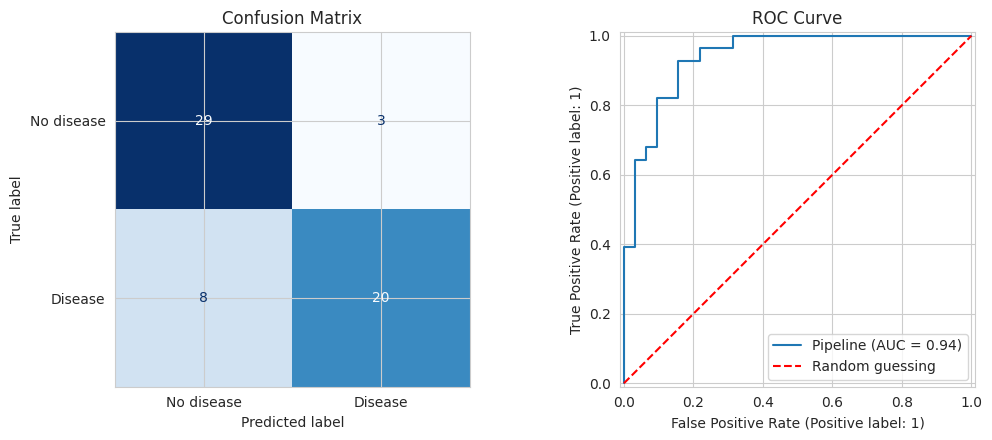

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test,
    display_labels=["No disease", "Disease"], cmap="Blues", colorbar=False, ax=ax[0]
)
ax[0].set_title("Confusion Matrix")

RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "r--", label="Random guessing")
ax[1].legend()
ax[1].set_title("ROC Curve")

plt.tight_layout()
plt.show()

**Insight:** Of 60 test patients, 29 healthy patients were correctly cleared and 20 sick patients were correctly found. There were 3 false alarms and 8 missed cases. Recall is 20/28 = 0.714, so at the default 0.5 threshold the model misses about 3 in 10 sick patients. Precision is 20/23 = 0.870. For a medical problem, those 8 missed patients are the main weakness, which is why the next section looks at the threshold.

## 7. Changing the Decision Threshold

The model outputs a probability, and 0.5 is only the default cut-off. In a medical setting, missing a sick patient is usually worse than a false alarm, so a lower threshold catches more sick patients (higher recall) at the cost of more false alarms (lower precision).

In [13]:
threshold_rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (proba >= t).astype(int)
    threshold_rows.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_test, pred_t),
        "Precision": precision_score(y_test, pred_t, zero_division=0),
        "Recall": recall_score(y_test, pred_t, zero_division=0),
    })
pd.DataFrame(threshold_rows).round(3)

,Threshold,Accuracy,Precision,Recall
0,0.3,0.850,0.788,0.929
1,0.4,0.850,0.828,0.857
2,0.5,0.817,0.870,0.714
3,0.6,0.817,0.870,0.714
4,0.7,0.800,0.900,0.643


**Insight:** Lowering the threshold from 0.5 to 0.3 raises recall from 0.714 to 0.929 (26 of 28 sick patients found instead of 20), but precision falls from 0.870 to 0.788 and false alarms rise from 3 to 7. A threshold of 0.4 is a middle option (recall 0.857, accuracy 0.850). Thresholds 0.5 and 0.6 give identical results because no test patient had a probability between them. These thresholds were compared on the test set, so treat this as an illustration of the trade-off, not a final tuned choice.

## 8. What Drives the Prediction?

Each coefficient shows how a feature pushes the probability up (positive) or down (negative). For numeric features, the effect is per **one standard deviation** increase. For categories, the effect is compared with the other groups of the same column.

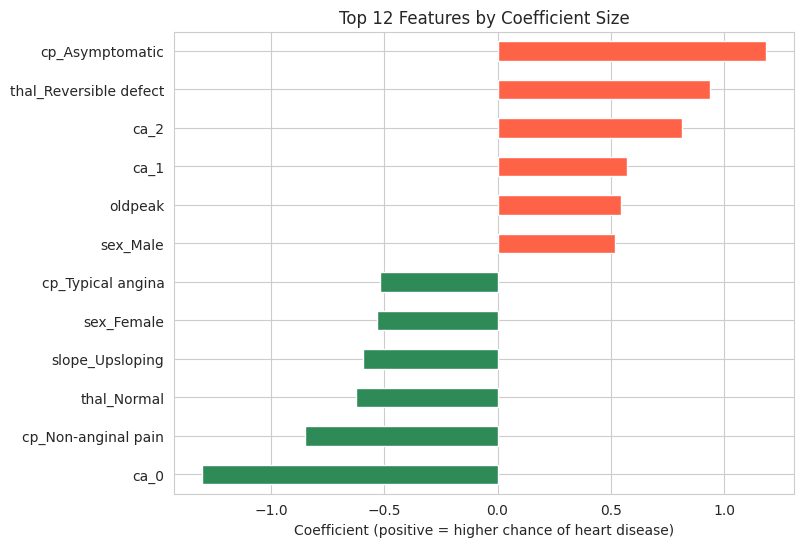

In [14]:
pre = best_model.named_steps["columntransformer"]
clf = best_model.named_steps["logisticregression"]

names = [n.replace("num__", "").replace("cat__", "") for n in pre.get_feature_names_out()]
coefs = pd.Series(clf.coef_[0], index=names)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).head(12).index).sort_values()

plt.figure(figsize=(8, 6))
top.plot(kind="barh", color=["seagreen" if v < 0 else "tomato" for v in top])
plt.xlabel("Coefficient (positive = higher chance of heart disease)")
plt.title("Top 12 Features by Coefficient Size")
plt.show()

**Insight:** The strongest signals raising the predicted risk are asymptomatic chest pain, a reversible thalassemia defect, 1 or 2 flagged vessels (`ca`), higher `oldpeak`, and being male. The strongest signals lowering it are 0 flagged vessels (`ca_0`), non-anginal pain, a normal thalassemia result, and an upsloping slope. Asymptomatic chest pain raising risk looks backwards, so it should not be read as "no symptoms causes disease". `sex_Male` and `sex_Female` appear as mirror images because they carry the same information.

## 9. Example Prediction

In [15]:
sample = X_test.iloc[[0]]
prob = best_model.predict_proba(sample)[0, 1]
actual = "Heart disease" if y_test.iloc[0] == 1 else "No heart disease"

print(sample.T)
print(f"\nPredicted probability of heart disease: {prob * 100:.1f}%")
print("Predicted class:", "Heart disease" if prob >= 0.5 else "No heart disease")
print("Actual class:   ", actual)

                      295
age                  41.0
trestbps            120.0
chol                157.0
thalach             182.0
oldpeak               0.0
sex                  Male
cp        Atypical angina
fbs                    No
restecg            Normal
exang                  No
slope           Upsloping
ca                      0
thal               Normal

Predicted probability of heart disease: 2.5%
Predicted class: No heart disease
Actual class:    No heart disease


## 10. Export the Model for the Website

Logistic Regression is just arithmetic: scale the numbers, add the 0/1 columns, multiply by the coefficients, add the intercept, and squeeze the result into a probability. So the learned numbers are saved to `model.json`, and the web page repeats the same steps in JavaScript.

In [16]:
scaler = pre.named_transformers_["num"]
ohe = pre.named_transformers_["cat"]

model_json = {
    "num_cols": NUM_COLS,
    "mean": scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),
    "cat_cols": CAT_COLS,
    "categories": [[str(v) for v in cats] for cats in ohe.categories_],
    "coef": clf.coef_[0].tolist(),
    "intercept": float(clf.intercept_[0]),
    "ranges": {c: [float(np.floor(X_train[c].min())), float(np.ceil(X_train[c].max()))] for c in NUM_COLS},
    "defaults_num": {c: float(round(X_train[c].median(), 1)) for c in NUM_COLS},
    "defaults_cat": {c: str(X_train[c].mode()[0]) for c in CAT_COLS},
    "test_accuracy": round(final["accuracy"] * 100, 1),
    "test_recall": round(final["recall"] * 100, 1),
}

with open("model.json", "w", encoding="utf-8") as f:
    json.dump(model_json, f, separators=(",", ":"), ensure_ascii=False)

print("model.json size: %.1f KB" % (os.path.getsize("model.json") / 1e3))

# Values for checking the website
check = X_test.iloc[0]
print("\nType these values into the website:")
for name, val in check.items():
    print(name, ":", val)
print("\nNotebook probability: %.1f%%" % (best_model.predict_proba(X_test.iloc[[0]])[0, 1] * 100))

try:
    from google.colab import files
    files.download("model.json")
except ImportError:
    pass

model.json size: 1.6 KB

Type these values into the website:
age : 41.0
trestbps : 120.0
chol : 157.0
thalach : 182.0
oldpeak : 0.0
sex : Male
cp : Atypical angina
fbs : No
restecg : Normal
exang : No
slope : Upsloping
ca : 0
thal : Normal

Notebook probability: 2.5%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Results Summary

In [17]:
print(f"Best C:                    {best_C}")
print(f"Baseline accuracy:         {baseline_acc:.3f}")
print(f"Model accuracy:            {final['accuracy']:.3f}")
print(f"Precision / Recall:        {final['precision']:.3f} / {final['recall']:.3f}")
print(f"ROC-AUC:                   {final['auc']:.3f}")
top_name = coefs.abs().idxmax()
print(f"Strongest signal: {top_name} (coefficient {coefs[top_name]:.2f}, lowers risk: no vessels flagged)")
print(f"Missed sick patients at 0.5 threshold: {int(((y_test == 1) & (pred == 0)).sum())} of {int((y_test == 1).sum())}")

Best C:                    1.0
Baseline accuracy:         0.533
Model accuracy:            0.817
Precision / Recall:        0.870 / 0.714
ROC-AUC:                   0.941
Strongest signal: ca_0 (coefficient -1.30, lowers risk: no vessels flagged)
Missed sick patients at 0.5 threshold: 8 of 28


##  12. Conclusion

Logistic Regression (C = 1, chosen by cross-validated ROC-AUC) reached 0.817 test accuracy against a 0.533 baseline, with ROC-AUC 0.941, precision 0.870 and recall 0.714. At the default 0.5 threshold it missed 8 of the 28 sick patients in the test set. Lowering the threshold to 0.3 raised recall to 0.929 at the cost of more false alarms (precision 0.788), which is usually the better trade-off for a medical problem. The results come from a small, single-hospital dataset, so they are an educational example, not a clinical tool.

## 13. Limitations and Next Steps

**Limitations**
- The dataset is small (about 300 patients), so the test set is only about 60 patients and the results can change a lot with a different split.
- All patients come from one hospital (Cleveland) and were already being tested for heart problems, so the model may not work for the general population.
- The model is an educational example, not a medical tool, and must not be used to diagnose anyone.
- Six patients with missing values were removed, which is about 2% of the data.
- The test set has only 28 sick patients, so each missed patient moves recall by about 3.6 points. The 0.714 recall could easily change with a different split.
- The thresholds were compared on the test set. A stricter approach would choose the threshold using cross-validated predictions on the training set (cross_val_predict).

**Next steps**
- Compare with other classifiers (K-Nearest Neighbors, Random Forest) on the same data
- Use cross-validation on the whole dataset for more stable results
- Try a larger heart-disease dataset